#### The Great Retrofit
J M Applegate  
May 23, 2024

This model is list-structured, where buildings reside in one of the appropriate lists:  
*to_do*, all buildings yet to be retrofitted,  
*queue*, building having requested a retrofit and awaiting assignment to a retrofit co-op,  
*projects*, in progress and in one of the co-op's project list, or  
*finished*, self expanatory.   

Each building has a time and cost for retrofit, where times are randomly assigned based on a mean and variance, and costs are calculated as mean weekly cost multiplied by retrofit time.  
*Could also calculate time from labour cost . . .  


Each co-op has an account, initially populated by the endowment value.  
Co-ops take on as many projects as they can fit in their budget given current account values.  
*Indicates labour is unlimited  

In [32]:
# import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import copy
plt.rc('font',**{'family':'sans-serif','sans-serif':['Futura']})
rng = np.random.default_rng()

##### Model parameters, currently invented by jma.

In [35]:
runs = 10
n = 100000 #number of building to retrofit
mean_time = 12 #mean weeks for retrofit
time_var = 4 #variance in retrofit times
week_cost = 1000 #mean weekly cost per retrofit
run_time = 100 * 52 #max number of weeks for model to run
tau = 100 #average new project requests per week (poisson)
n_co_ops = 100 #number of retrofit co-ops
surplus = .2 #percentage surplus for co-op
E = 100000 #initial co-op endowment

results_labels = ['run', 'n', 'n_co_ops', 'E', 'mean_time', 'week_cost', 'tau', 'to_do', 'queued', 'with_capacity', 
                  'in_progress', 'finished', 'time', 'accounts']

##### The Model

In [36]:
#results = []
step_results = []

#for n in [100, 1000, 10000, 100000, 200000]:
for n_coops in [1, 10, 25, 50, 75, 100, 200]:
#for E in [30000]:#[10000, 20000, 40000, 60000, 80000, 100000]:

    print('parameter', n_coops)
    
    for r in range(runs):
        
        print(r, end =" ")
        
        to_do = list(range(n)) #list of buildings needing retrofit
        queued = [] #list of buildings awaiting retrofit work
        times = rng.choice(2 * time_var, n) - time_var + mean_time #time to retrofit for each building
        costs = week_cost * times #cost of retrofit for each building
        projects = [[] for i in range(n_co_ops)] #list of each co-ops retrofit projects
        finished = [] #buildings with completed retrofits
        accounts = [E] * n_co_ops #account balances for each co-op
        
        for t in range(run_time):

            #print('t', t)
            
            #Buildings decide to retrofit
            #print('to_do', len(to_do))
            if to_do:
                n_requests = min(rng.poisson(tau), len(to_do))
                queued = queued + list(rng.choice(to_do, size = n_requests, replace = False))
                to_do = list(set(to_do).difference(queued))
            #print('queued', queued)
            
            #Buildings wanting retrofits are assigned to retrofit co-ops.
            #print('accounts', accounts)
            for b in queued.copy():
                estimate = costs[b]
                #print('p', b, 'estimate', estimate)
                with_capacity = [c for c in range(n_co_ops) if sum([times[x] * week_cost for x in projects[c]]) + estimate <= accounts[c]]
                #print('with_capacity', with_capacity)
                if not with_capacity: 
                    #print('no extra capacity')
                    break
                c = rng.choice(with_capacity)
                projects[c].append(queued.pop(0))
                #print('projects', projects)
            
            #Co-ops do work on buildings
            for c in range(n_co_ops):
                for p in copy.deepcopy(projects)[c]:
                    #print('project', p, 'time', times[p])
                    if times[p] == 0: 
                        projects[c].remove(p)
                        finished.append(p)
                        accounts[c] += (1 + surplus) * costs[p] 
                    else: 
                        if accounts[c] >= week_cost:
                            times[p] -= 1
                            accounts[c] -= week_cost
                    #print('projects', projects)
                            
            #print('finished', finished)

            step_results.append([r, n, n_co_ops, E, mean_time, week_cost, tau, len(to_do), len(queued), len(with_capacity), 
                                 len([b for c in projects for b in c]), len(finished), t, sum(accounts)])

            #print(len(finished))
            if len(finished) == n: break

        #run_results.append([r, n, n_co_ops, E, mean_time, week_cost, tau, len(to_do), len(queued), len(with_capacity), 
                                 #len([b for c in projects for b in c]), len(finished), t, sum(accounts)])

    print("\n")
print('complete')

parameter 1
0 1 2 3 4 5 6 7 8 9 

parameter 10
0 1 2 3 4 5 6 7 8 9 

parameter 25
0 1 2 3 4 5 6 7 8 9 

parameter 50
0 1 2 3 4 5 6 7 8 9 

parameter 75
0 1 2 3 4 5 6 7 8 9 

parameter 100
0 1 2 3 4 5 6 7 8 9 

parameter 200
0 1 2 3 4 5 6 7 8 9 

complete


In [37]:
results_frame = pd.DataFrame(step_results, columns = results_labels)

In [38]:
results_frame.to_csv('results_E100k_n100k_ncsweep_tau100_steps_v2.csv', index = False)
#results_frame = pd.read_csv('results_E30k_n1000_nc10_tau10_steps_v2.csv')

In [29]:
plot_data = results_frame[['run', 'time', 'in_progress', 'finished', 'queued', 'accounts', 'to_do']]['n

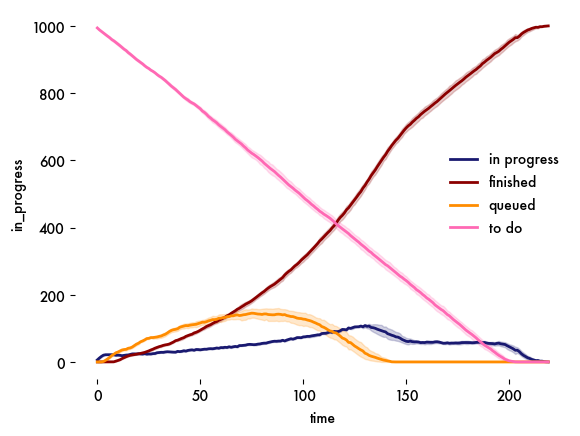

In [30]:
sns.lineplot(x = 'time', y = 'in_progress', data = plot_data, legend = True, color = 'midnightblue', linewidth = 2, label = 'in progress')
sns.lineplot(x = 'time', y = 'finished', data = plot_data, legend = True, color = 'darkred', linewidth = 2, label = 'finished')
sns.lineplot(x = 'time', y = 'queued', data = plot_data, legend = True, color = 'darkorange', linewidth = 2, label = 'queued')
sns.lineplot(x = 'time', y = 'to_do', data = plot_data, legend = True, color = 'hotpink', linewidth = 2, label = 'to do')
plt.legend(frameon=False)
sns.despine(left = True, bottom = True)

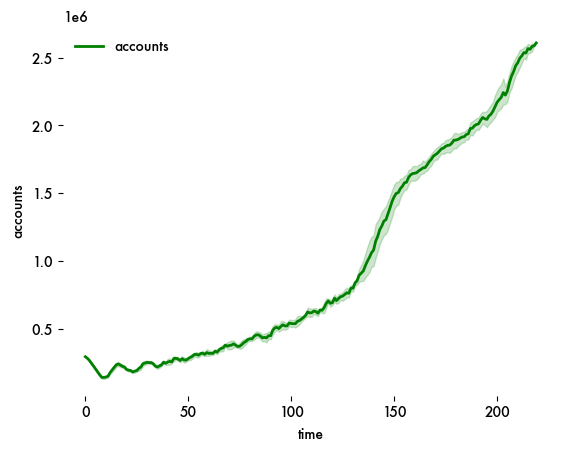

In [31]:
sns.lineplot(x = 'time', y = 'accounts', data = plot_data, legend = True, color = 'green', linewidth = 2, label = 'accounts')
plt.legend(frameon=False)
sns.despine(left = True, bottom = True)